**Import Library & Upload Data**

In [1]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
import re
from google.colab import files

print("Silakan unggah file Excel kuesioner Anda:")
up = files.upload()
nama_file = list(up.keys())[0]
print(f"File terbaca: {nama_file}")

Silakan unggah file Excel kuesioner Anda:


Saving data mahasiswa.xlsx to data mahasiswa.xlsx
File terbaca: data mahasiswa.xlsx


**Membaca & Menyiapkan Data**

In [3]:
JUMLAH_KOLOM_DEMOGRAFI = 5 # Ubah jika jumlah kolom demografi di excel bukan 5
df = pd.read_excel(nama_file)
butir = df.iloc[:, JUMLAH_KOLOM_DEMOGRAFI:]

print("Jumlah responden:", len(df))
print("Jumlah butir:", butir.shape[1])

skala = {
    "Sangat Tidak Setuju (STS)": 1,
    "Tidak Setuju (TS)": 2,
    "Netral (N)": 3,
    "Setuju (S)": 4,
    "Sangat Setuju (SS)": 5,
}

num = butir.replace(skala).apply(pd.to_numeric, errors="coerce")
print("Sel yang gagal dikonversi (harus 0):", int(num.isna().sum().sum()))

dimensi = {}
for kolom in butir.columns:
    nama = re.match(r"^(.*?) \[", kolom)
    if nama:
        nama = nama.group(1).strip()
        dimensi.setdefault(nama, []).append(kolom)

for nama, daftar in dimensi.items():
    print(f"{nama}: {len(daftar)} butir")
print("\nData siap diproses!")

Jumlah responden: 181
Jumlah butir: 31
Sel yang gagal dikonversi (harus 0): 195
Penggunaan AI pada tugas atau projek kuliah: 7 butir
Aspek Psikologis penggunaan AI pada tugas atau projek kuliah: 7 butir
Kebiasaan penggunaan teknologi digital: 6 butir
Prokrastinasi akademik.: 4 butir
Rsspon emosional: 5 butir

Data siap diproses!


/tmp/ipykernel_2622/643737380.py:16: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  num = butir.replace(skala).apply(pd.to_numeric, errors="coerce")


**Pengujian Validitas, Reliabilitas, dan Visualisasi Grafik**

n = 181 | r tabel (alpha=0,05; df=179) = 0.146

Grafik tersimpan: Grafik_Dimensi_Penggunaan_AI_pada_tugas_atau_projek_kuliah.png


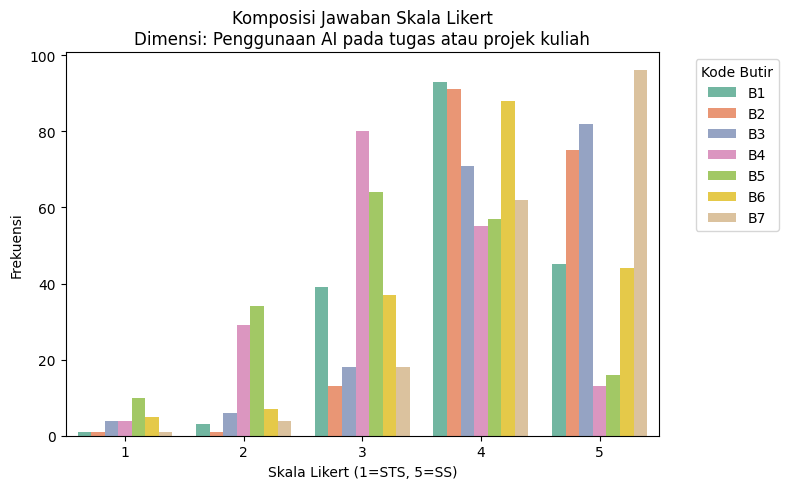

Grafik tersimpan: Grafik_Dimensi_Aspek_Psikologis_penggunaan_AI_pada_tugas_atau_projek_kuliah.png


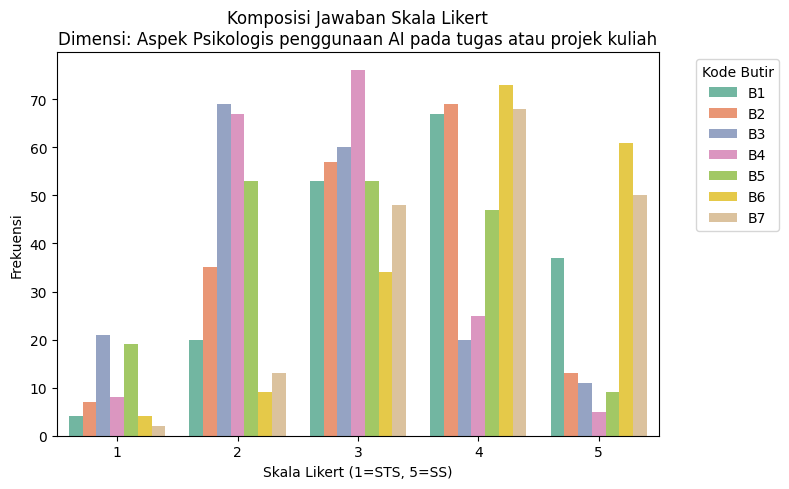

Grafik tersimpan: Grafik_Dimensi_Kebiasaan_penggunaan_teknologi_digital.png


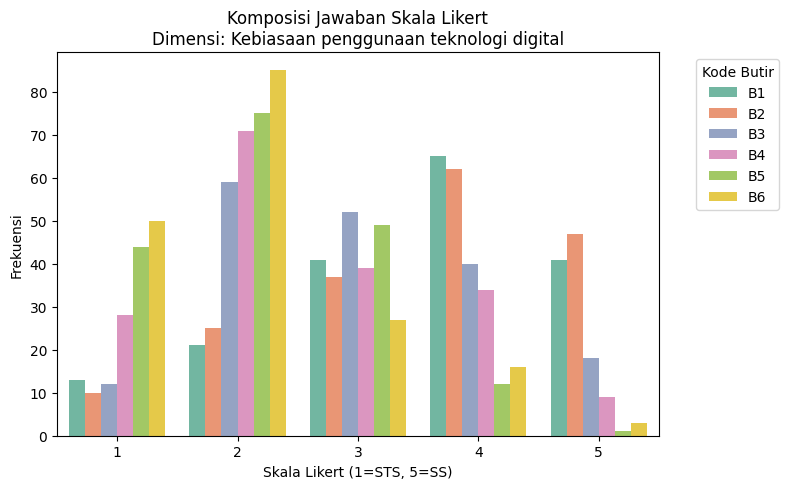

Grafik tersimpan: Grafik_Dimensi_Prokrastinasi_akademik..png


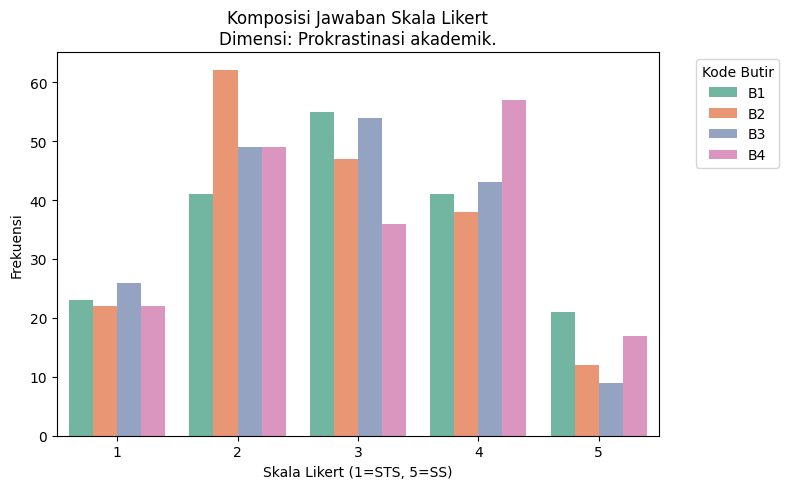

Grafik tersimpan: Grafik_Dimensi_Rsspon_emosional.png


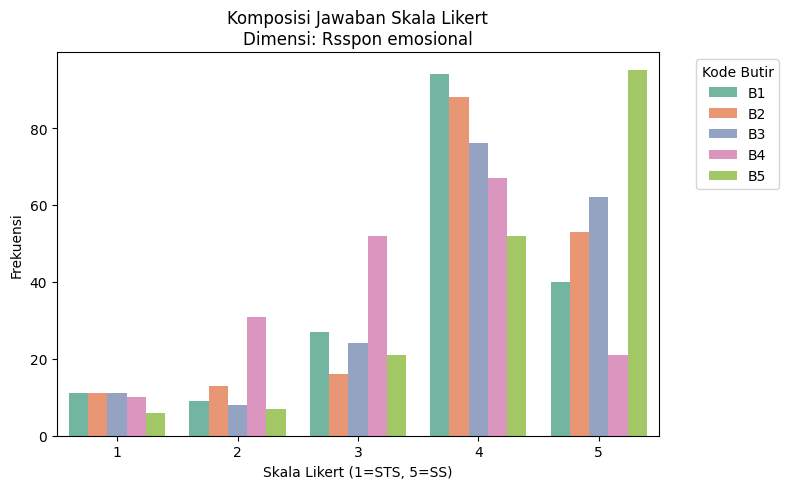

In [4]:
n = len(num)
t = stats.t.ppf(0.975, n-2)
r_tabel = t / np.sqrt((n-2) + t**2)
print(f"n = {n} | r tabel (alpha=0,05; df={n-2}) = {r_tabel:.3f}\n")

hasil_validitas = []
hasil_reliabilitas = []
alpha_dihapus = []
hasil_deskriptif = []

def cronbach_alpha(x):
    k = x.shape[1]
    if k < 2: return 0
    return (k / (k - 1)) * (1 - x.var(ddof=1).sum() / x.sum(axis=1).var(ddof=1))

def kategori(a):
    return ("Sangat baik" if a >= 0.90 else "Baik" if a >= 0.80
            else "Reliabel" if a >= 0.70 else "Tidak reliabel")

for nama, daftar in dimensi.items():
    x = num[daftar]
    total = x.sum(axis=1)

    # Uji Validitas
    for i, kolom in enumerate(daftar, 1):
        r, p = stats.pearsonr(x[kolom], total)
        r_koreksi, _ = stats.pearsonr(x[kolom], total - x[kolom])
        hasil_validitas.append({
            "Dimensi": nama,
            "Butir": f"B{i}",
            "r hitung": round(r, 3),
            "Corrected r": round(r_koreksi, 3),
            "p-value": round(p, 4),
            "Keterangan": "Valid" if r > r_tabel else "Tidak valid"
        })

    # Uji Reliabilitas
    a = cronbach_alpha(x)
    hasil_reliabilitas.append({
        "Dimensi": nama,
        "Jumlah butir": len(daftar),
        "Cronbach's alpha": round(a, 3),
        "Kategori": kategori(a)
    })

    for i, kolom in enumerate(daftar, 1):
        if len(daftar) > 2:
            alpha_dihapus.append({
                "Dimensi": nama,
                "Butir": f"B{i}",
                "Alpha jika dihapus": round(cronbach_alpha(x.drop(columns=kolom)), 3)
            })

    # Analisis Deskriptif (Std, Skewness, Kurtosis)
    std_dev = round(total.std(), 3)
    skewness = round(total.skew(), 3)
    kurtosis = round(total.kurtosis(), 3)

    hasil_deskriptif.append({
        "Dimensi": nama,
        "Mean Total Skor": round(total.mean(), 3),
        "Standar Deviasi": std_dev,
        "Skewness": skewness,
        "Kurtosis": kurtosis
    })

    # Visualisasi
    plt.figure(figsize=(8, 5))
    x_melted = x.melt(var_name='Butir', value_name='Jawaban')
    butir_mapping = {kol: f"B{idx+1}" for idx, kol in enumerate(daftar)}
    x_melted['Butir'] = x_melted['Butir'].map(butir_mapping)

    sns.countplot(data=x_melted, x='Jawaban', hue='Butir', palette='Set2')
    plt.title(f'Komposisi Jawaban Skala Likert\nDimensi: {nama}')
    plt.xlabel('Skala Likert (1=STS, 5=SS)')
    plt.ylabel('Frekuensi')
    plt.legend(title='Kode Butir', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()

    nama_file_grafik = f"Grafik_Dimensi_{nama.replace(' ', '_')}.png"
    plt.savefig(nama_file_grafik)
    print(f"Grafik tersimpan: {nama_file_grafik}")
    plt.show()

**Export Hasil ke Excel & Download**

In [5]:
tabel_validitas = pd.DataFrame(hasil_validitas)
tabel_reliabilitas = pd.DataFrame(hasil_reliabilitas)
tabel_alpha_dihapus = pd.DataFrame(alpha_dihapus)
tabel_deskriptif = pd.DataFrame(hasil_deskriptif)

gabung = tabel_validitas.merge(tabel_alpha_dihapus, on=["Dimensi", "Butir"], how="left")

file_output = "Hasil_Pengujian_Kuesioner_Lengkap.xlsx"
with pd.ExcelWriter(file_output) as w:
    gabung.to_excel(w, sheet_name="Validitas", index=False)
    tabel_reliabilitas.to_excel(w, sheet_name="Reliabilitas", index=False)
    tabel_deskriptif.to_excel(w, sheet_name="Statistik_Deskriptif", index=False)

files.download(file_output)
print(f"\nProses selesai. File {file_output} telah diunduh.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Proses selesai. File Hasil_Pengujian_Kuesioner_Lengkap.xlsx telah diunduh.
